# 🔗 Live Deployment Link

**Heart Disease Prediction System (live):** PASTE_HEART_DEPLOYMENT_LINK_HERE

**Titanic Passenger Survival Prediction System (live):** PASTE_TITANIC_DEPLOYMENT_LINK_HERE

**GitHub Repository:** https://github.com/fatimafarzad123/Titanic-Passenger-Survival-Model

| | |
|---|---|
| **Student Name** | Fatima Farzad |
| **Registration No.** | SP24-BSE-025 |
| **Course** | Machine Learning Fundamentals (AIC354) |
| **Instructor** | Dr. Rao Muhammad Adeel Nawab |
| **Assignment** | Assignment 2 – Task 2: Heart Disease Prediction System |

# Heart Disease Prediction System

## Setup: Running This Notebook From Scratch

Run these commands in a terminal, inside this project's folder, before opening the notebook.

```
python -m venv venv
venv\Scripts\activate            # Windows  (macOS/Linux: source venv/bin/activate)
pip install -r requirements.txt
jupyter notebook
```

Keep `heart-disease-uci-cleveland.csv` in the same folder as this notebook.

## Introduction

##### **Definition** A binary classification ML task that predicts whether a patient has heart disease (Yes) or not (No) using their clinical attributes (e.g., chest pain type, exercise-induced angina, number of major vessels, thalassemia).
##### **Application** It can support doctors in screening patients for coronary heart disease before costly and risky tests like angiography, and is widely used for learning and comparing ML algorithms on medical data.

## Dataset

- **Source:** UCI Machine Learning Repository – Heart Disease Dataset (https://archive.ics.uci.edu/dataset/45/heart+disease)
- **File used:** Cleveland Clinic Foundation data (`processed.cleveland.data`), the most complete and widely used part of the UCI Heart Disease dataset, saved here as `heart-disease-uci-cleveland.csv` with the UCI column names.
- **Size:** 303 patients, 13 input attributes + 1 output attribute. Missing values are marked `?` (4 in `ca`, 2 in `thal`).
- **Output:** UCI's `num` attribute (0 = no disease, 1–4 = disease present) is used as presence (1) vs absence (0), as recommended by UCI. In this file it is the `target` column.

## Selected Input Attributes (Constraint: only 4)

| UCI Attribute | Name in this Notebook | Meaning | Why selected |
|---|---|---|---|
| `cp` | **ChestPain** | Type of chest pain | Asymptomatic chest pain is strongly linked to heart disease |
| `exang` | **ExerciseAngina** | Chest pain caused by exercise | A classic sign of blocked arteries |
| `ca` | **Vessels** | Number of major vessels coloured by fluoroscopy (0–3) | More blocked vessels → higher risk |
| `thal` | **Thal** | Thallium stress test result | Reversible defects indicate poor blood flow to the heart |

All four are **categorical**, exactly like the four Titanic inputs, so the same Label Encoding + SVC approach can be used.

## Input and Output

### Inputs (Features / Attributes)

| **Input Feature/Attribute** | **Possible Values** |
| --------------- | ------------------------------------------------------------ |
| **ChestPain**      | Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic |
| **ExerciseAngina** | Yes, No |
| **Vessels**        | Zero, One, Two, Three |
| **Thal**           | Normal, Fixed Defect, Reversible Defect |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| -------------------- | ------------------- |
| **HeartDisease**     | Yes, No |

### Examples (Heart Disease Dataset)

| ChestPain | ExerciseAngina | Vessels | Thal | HeartDisease |
| :-------: | :------------: | :-----: | :--: | :----------: |
| Typical Angina | No | Zero | Fixed Defect | No |
| Asymptomatic | Yes | Three | Normal | Yes |
| Asymptomatic | Yes | Two | Reversible Defect | Yes |
| Non-Anginal Pain | No | Zero | Normal | No |
| Atypical Angina | No | Zero | Normal | No |

## Developer & System Information

| | |
| --- | --- |
| **Developer Name** | Fatima Farzad (SP24-BSE-025) |
| **Program Name** | heart_disease_project |
| **IDE** | Jupyter Notebook |
| **Programming Language** | Python 3 |
| **Libraries** | NumPy, Pandas, Pickle (built-in), scikit-learn, PrettyTable, Matplotlib, Seaborn |
| **Based on** | Titanic Passenger Survival Prediction System by Mr. Mohsin Afzal and Dr. Rao Muhammad Adeel Nawab |

## Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data
- Step 4: Feature Extraction
- Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)
  - Step 5.1: Train the Label Encoder
  - Step 5.2: Label Encode the Output
  - Step 5.3: Label Encode the Input
- Step 6: Execute the Training Phase
  - Step 6.1: Splitting Sample Data into Training Data and Testing Data
  - Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data
  - Step 6.3: Train the Support Vector Classifier
  - Step 6.4: Save the Trained Model
- Step 7: Execute the Testing Phase
  - Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data
  - Step 7.2: Load the Saved Model
  - Step 7.3: Evaluate the Machine Learning Model
    - Step 7.3.1: Make Predictions with the Trained Models on Testing Data
  - Step 7.4: Calculate the Accuracy Score
  - Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)
- Step 8: Execute the Application Phase
  - Step 8.1: Take Input from User
  - Step 8.2: Convert User Input into Feature Vector
  - Step 8.3: Label Encoding of Feature Vector
  - Step 8.4: Load the Saved Model
  - Step 8.5: Model Prediction
    - Step 8.5.1: Apply Model and Return Prediction to the User
- Step 9: Execute the Feedback Phase
  - Step 9.1: Collect Feedback from User
  - Step 9.2: Make a List of Potential Improvements
  - Step 9.3: Improve the Model Based on Feedback
- Step 10: Deploy the Model on the Cloud

## Code – Heart Disease Prediction

### Step 1: Import Libraries

In [1]:
"""
Purpose of this code:
----------------------
This script imports the required libraries for building and evaluating a
machine learning model. It sets up tools for data manipulation, preprocessing,
splitting datasets, training a Support Vector Machine (SVM) model,
evaluating accuracy, and displaying results in tabular form.
"""

# Import numerical computing library (used for arrays, math operations, etc.)
import numpy as np

# Import data manipulation library (used for DataFrames, reading/writing data, etc.)
import pandas as pd

# Import pickle (used for saving and loading Python objects/models)
import pickle

# Import train_test_split (used to divide dataset into training and testing sets)
from sklearn.model_selection import train_test_split

# Import LabelEncoder (used to convert categorical values into numeric codes)
from sklearn.preprocessing import LabelEncoder

# Import Support Vector Machine (SVM) model from scikit-learn
from sklearn import svm

# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Import PrettyTable (used to display results in a clean, table format)
from prettytable import PrettyTable

# Import plotting libraries (used for the confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Sample Data

In [2]:
"""
Purpose of this section:
-------------------------
This part of the code loads the UCI Heart Disease (Cleveland) dataset from a
CSV file into a pandas DataFrame. Missing values in the UCI file are marked
with '?', so we tell pandas to treat '?' as missing (NaN).
"""

# Read the CSV file and load it into a pandas DataFrame
# 'heart-disease-uci-cleveland.csv' should be present in the working directory
raw_data = pd.read_csv("heart-disease-uci-cleveland.csv", na_values="?")

# Print a header to indicate that the raw data is being displayed
print("\n\nRaw UCI Heart Disease Data (first 10 rows):")
print("===========================================\n")

# Configure pandas to display all columns (so nothing gets hidden with '...')
pd.set_option("display.max_rows", None, "display.max_columns", None, "display.width", 200)

# Print the first 10 rows of the raw dataset
print(raw_data.head(10))
print("\nShape of raw data (rows, columns):", raw_data.shape)



Raw UCI Heart Disease Data (first 10 rows):

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope   ca  thal  target
0   63    1   1       145   233    1        2      150      0      2.3      3  0.0   6.0       0
1   67    1   4       160   286    0        2      108      1      1.5      2  3.0   3.0       1
2   67    1   4       120   229    0        2      129      1      2.6      2  2.0   7.0       1
3   37    1   3       130   250    0        0      187      0      3.5      3  0.0   3.0       0
4   41    0   2       130   204    0        2      172      0      1.4      1  0.0   3.0       0
5   56    1   2       120   236    0        0      178      0      0.8      1  0.0   3.0       0
6   62    0   4       140   268    0        2      160      0      3.6      3  2.0   3.0       1
7   57    0   4       120   354    0        0      163      1      0.6      1  0.0   3.0       0
8   63    1   4       130   254    0        2      147      0      1.4      2  1

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [3]:
"""
Purpose of this section:
-------------------------
This part of the code helps us understand the dataset by:
1. Printing the names of all attributes (columns) in the DataFrame.
2. Showing the total number of instances (rows) available in the dataset.
3. Checking for missing values and the class distribution of the output.
"""

# Display all column names (attributes) in the dataset
print("\n\nAttributes in Raw Data:")
print("=======================\n")
print(raw_data.columns)

# Total number of instances
print("\n\nNumber of Instances in Raw Data:", raw_data["age"].count())
print("=====================================\n")

# Missing values per attribute
print("Missing Values per Attribute:")
print("=============================\n")
print(raw_data.isnull().sum())

# Class distribution of output (0 = no heart disease, 1 = heart disease)
print("\n\nClass Distribution of Output (target):")
print("======================================\n")
print(raw_data["target"].value_counts())



Attributes in Raw Data:

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'], dtype='str')


Number of Instances in Raw Data: 303

Missing Values per Attribute:

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


Class Distribution of Output (target):

target
0    164
1    139
Name: count, dtype: int64


#### Step 3.2: Pre-process Sample Data
Unlike the Titanic sample data, the UCI data is **not** ready to use, so three pre-processing steps are performed:
1. **Attribute selection:** keep only the 4 selected input attributes (`cp`, `exang`, `ca`, `thal`) and the output (`target`).
2. **Handle missing values:** remove the 6 rows where `ca` or `thal` is missing (`?`).
3. **Convert numeric codes to readable categories** (e.g., `cp = 4` → `Asymptomatic`), so the data has the same form as the Titanic sample data (text categories that are then label-encoded).

In [4]:
"""
Purpose of this section:
-------------------------
This part of the code converts the raw UCI data into clean Sample Data with
4 categorical input attributes and 1 categorical output attribute, and saves
it as 'sample-data.csv' (same file name as in the Titanic project).
"""

# 1. Attribute selection: keep only the 4 selected inputs and the output
selected_data = raw_data[["cp", "exang", "ca", "thal", "target"]]

# 2. Handle missing values: remove rows that contain any missing value
print("Rows before removing missing values:", len(selected_data))
selected_data = selected_data.dropna().reset_index(drop=True)
print("Rows after removing missing values: ", len(selected_data))

# 3. Convert UCI numeric codes into readable category names (see UCI documentation)
chest_pain_names = {1: "Typical Angina", 2: "Atypical Angina", 3: "Non-Anginal Pain", 4: "Asymptomatic"}
exercise_angina_names = {0: "No", 1: "Yes"}
vessels_names = {0: "Zero", 1: "One", 2: "Two", 3: "Three"}
thal_names = {3: "Normal", 6: "Fixed Defect", 7: "Reversible Defect"}
heart_disease_names = {0: "No", 1: "Yes"}

sample_data = pd.DataFrame({
    "ChestPain": selected_data["cp"].astype(int).map(chest_pain_names),
    "ExerciseAngina": selected_data["exang"].astype(int).map(exercise_angina_names),
    "Vessels": selected_data["ca"].astype(int).map(vessels_names),
    "Thal": selected_data["thal"].astype(int).map(thal_names),
    "HeartDisease": selected_data["target"].astype(int).map(heart_disease_names),
})

# Save the clean sample data to a CSV file
sample_data.to_csv(r"sample-data.csv", index=False, header=True)
print("\nSaved: sample-data.csv")

# Print the complete pre-processed Sample Data
print("\n\nSample Data (after pre-processing):")
print("===================================\n")
print(sample_data)

Rows before removing missing values: 303
Rows after removing missing values:  297

Saved: sample-data.csv


Sample Data (after pre-processing):

            ChestPain ExerciseAngina Vessels               Thal HeartDisease
0      Typical Angina             No    Zero       Fixed Defect           No
1        Asymptomatic            Yes   Three             Normal          Yes
2        Asymptomatic            Yes     Two  Reversible Defect          Yes
3    Non-Anginal Pain             No    Zero             Normal           No
4     Atypical Angina             No    Zero             Normal           No
5     Atypical Angina             No    Zero             Normal           No
6        Asymptomatic             No     Two             Normal          Yes
7        Asymptomatic            Yes    Zero             Normal           No
8        Asymptomatic             No     One  Reversible Defect          Yes
9        Asymptomatic            Yes    Zero  Reversible Defect          Yes
10      

#### Step 4: Feature Extraction
o   Features are already Extracted (the 4 selected attributes are used directly as features)

o   No Feature Extraction needs to be Performed

### Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)

#### Step 5.1: Train the Label Encoder

In [5]:
"""
Purpose of this section:
-------------------------
This part of the code sets up and trains Label Encoders.
Label Encoding is used to convert categorical values (like 'Asymptomatic',
'Normal', 'Yes') into numeric codes that machine learning algorithms can work with.

Steps:
1. Define sample label categories for each attribute.
2. Initialize a LabelEncoder for each attribute.
3. Train (fit) each LabelEncoder with its respective category values.
"""

# Define label categories for each feature
# These are possible values each column can have in the dataset
chest_pain = pd.DataFrame({"ChestPain": ["Typical Angina", "Atypical Angina", "Non-Anginal Pain", "Asymptomatic"]})
exercise_angina = pd.DataFrame({"ExerciseAngina": ["Yes", "No"]})
vessels = pd.DataFrame({"Vessels": ["Zero", "One", "Two", "Three"]})
thal = pd.DataFrame({"Thal": ["Normal", "Fixed Defect", "Reversible Defect"]})
heart_disease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

# Create LabelEncoder objects for each categorical column
chest_pain_label_encoder = LabelEncoder()
exercise_angina_label_encoder = LabelEncoder()
vessels_label_encoder = LabelEncoder()
thal_label_encoder = LabelEncoder()
heart_disease_label_encoder = LabelEncoder()

# Train (fit) the encoders on the given categories
# np.ravel() flattens the DataFrame column into a 1D array for the encoder
chest_pain_label_encoder.fit(np.ravel(chest_pain))
exercise_angina_label_encoder.fit(np.ravel(exercise_angina))
vessels_label_encoder.fit(np.ravel(vessels))
thal_label_encoder.fit(np.ravel(thal))
heart_disease_label_encoder.fit(np.ravel(heart_disease))

# Show the numeric code assigned to every category
for name, encoder in [("ChestPain", chest_pain_label_encoder),
                      ("ExerciseAngina", exercise_angina_label_encoder),
                      ("Vessels", vessels_label_encoder),
                      ("Thal", thal_label_encoder),
                      ("HeartDisease", heart_disease_label_encoder)]:
    print(f"{name:15s}", dict(zip(encoder.classes_, encoder.transform(encoder.classes_).tolist())))

ChestPain       {'Asymptomatic': 0, 'Atypical Angina': 1, 'Non-Anginal Pain': 2, 'Typical Angina': 3}
ExerciseAngina  {'No': 0, 'Yes': 1}
Vessels         {'One': 0, 'Three': 1, 'Two': 2, 'Zero': 3}
Thal            {'Fixed Defect': 0, 'Normal': 1, 'Reversible Defect': 2}
HeartDisease    {'No': 0, 'Yes': 1}


#### Step 5.2: Label Encode the Output

In [6]:
"""
Purpose of this section:
-------------------------
This part of the code applies Label Encoding to the target/output variable
("HeartDisease") in the dataset. The categorical values ("Yes", "No") are
converted into numerical values (1 and 0) that can be used by
machine learning algorithms.
"""

# Create copies of the dataset (one for encoded output, one to keep original)
sample_data_encoded_output = sample_data.copy()
original_sample_data = sample_data.copy()

# Transform "HeartDisease" (categorical -> numeric) using the trained LabelEncoder
print("\n\nHeartDisease Attribute After Label Encoding:")
print("============================================\n")
sample_data["encoded_heart_disease"] = heart_disease_label_encoder.transform(sample_data["HeartDisease"])

# Show original "HeartDisease" values and their numeric encodings
print(sample_data[["HeartDisease", "encoded_heart_disease"]])

# Replace original categorical columns with encoded values for the output dataset
sample_data_encoded_output[["ChestPain", "ExerciseAngina", "Vessels", "Thal", "HeartDisease"]] = \
    sample_data[["ChestPain", "ExerciseAngina", "Vessels", "Thal", "encoded_heart_disease"]]

# Save the encoded dataset to a CSV file (useful for training/testing later)
sample_data_encoded_output.to_csv(r"sample-data-encoded-output.csv", index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")



HeartDisease Attribute After Label Encoding:

    HeartDisease  encoded_heart_disease
0             No                      0
1            Yes                      1
2            Yes                      1
3             No                      0
4             No                      0
5             No                      0
6            Yes                      1
7             No                      0
8            Yes                      1
9            Yes                      1
10            No                      0
11            No                      0
12           Yes                      1
13            No                      0
14            No                      0
15            No                      0
16           Yes                      1
17            No                      0
18            No                      0
19            No                      0
20            No                      0
21            No                      0
22           Yes                

#### Step 5.3: Label Encode the Input

In [7]:
"""
Purpose of this section:
-------------------------
This part of the code applies Label Encoding to the input features
("ChestPain", "ExerciseAngina", "Vessels", "Thal"). Each categorical value
is converted into a numeric value so that machine learning models
can process them.
"""

# Create copies of the dataset (to keep original values safe)
sample_data_encoded = sample_data_encoded_output.copy()

# Encode each input attribute
sample_data_encoded_output["encoded_chest_pain"] = chest_pain_label_encoder.transform(sample_data_encoded_output["ChestPain"])
sample_data_encoded_output["encoded_exercise_angina"] = exercise_angina_label_encoder.transform(sample_data_encoded_output["ExerciseAngina"])
sample_data_encoded_output["encoded_vessels"] = vessels_label_encoder.transform(sample_data_encoded_output["Vessels"])
sample_data_encoded_output["encoded_thal"] = thal_label_encoder.transform(sample_data_encoded_output["Thal"])

# Replace categorical columns with encoded values in the dataset
sample_data_encoded[["ChestPain", "ExerciseAngina", "Vessels", "Thal", "HeartDisease"]] = \
    sample_data_encoded_output[["encoded_chest_pain", "encoded_exercise_angina", "encoded_vessels", "encoded_thal", "HeartDisease"]]

# Make sure every column is stored as an integer
sample_data_encoded = sample_data_encoded.astype(int)

# Print encoded dataset (with numeric values instead of categories)
print("\n\nSample Data after Label Encoding:")
print("=================================\n")
print(sample_data_encoded)

# Save the encoded dataset to a new CSV file
sample_data_encoded.to_csv(r"sample-data-encoded.csv", index=False, header=True)



Sample Data after Label Encoding:

     ChestPain  ExerciseAngina  Vessels  Thal  HeartDisease
0            3               0        3     0             0
1            0               1        1     1             1
2            0               1        2     2             1
3            2               0        3     1             0
4            1               0        3     1             0
5            1               0        3     1             0
6            0               0        2     1             1
7            0               1        3     1             0
8            0               0        0     2             1
9            0               1        3     2             1
10           0               0        3     0             0
11           1               0        3     1             0
12           2               1        0     0             1
13           1               0        3     2             0
14           2               0        3     2             0
15 

### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [8]:
"""
Purpose of this section:
-------------------------
This part of the code splits the dataset into Training Data and Testing Data.
- Training Data is used to teach the machine learning model.
- Testing Data is used to check how well the model performs on unseen data.
"""

# Split dataset into training (80%) and testing (20%)
# random_state=0 ensures reproducibility (same split every time)
# shuffle=False keeps the original order of rows (no shuffling before splitting)
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=False
)

# Save the training and testing datasets to CSV files
training_data_encoded.to_csv(r"training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv(r"testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)

Training Data shape: (237, 5)
Testing Data shape: (60, 5)


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [9]:
"""
Purpose of this section:
-------------------------
This part of the code separates the features (input vectors) and
the labels (output values) from the training dataset.
"""

# Extract input vectors (features) from training data
input_vector_train = training_data_encoded.iloc[:, :-1]

# Extract output labels (target variable) from training data
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (237, 4)
Output labels (train) shape: (237,)


### 6.3: Train the Support Vector Classifier

In [10]:
"""
Purpose of this section:
-------------------------
This part of the code trains a Support Vector Classifier (SVC) on the training data.
The SVC is a type of machine learning model that finds the best boundary
to separate different classes (e.g., heart disease vs. no heart disease).
"""

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

# Initialize the Support Vector Classifier with chosen parameters
svc_model = svm.SVC(gamma="auto", random_state=0)

# Train the model using the training data (features and labels)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

# Print trained model details (parameters and values)
print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


### Step 6.4: Save the Trained Model

In [11]:
"""
Purpose of this section:
-------------------------
This part of the code saves the trained Support Vector Classifier (SVC)
model to your computer so it can be reused later without retraining.
"""

# Save the trained SVC model to a file named "svc_trained_model.pkl"
pickle.dump(svc_model, open("svc_trained_model.pkl", "wb"))
print("Saved: svc_trained_model.pkl")

Saved: svc_trained_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [12]:
"""
Purpose of this section:
-------------------------
This part of the code separates the features (inputs) and the labels (outputs)
from the testing dataset.
"""

input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (60, 4)
Output labels (test) shape: (60,)


### Step 7.2: Load the Saved Model

In [13]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved Support Vector Classifier (SVC)
model from disk into memory.
"""

model = pickle.load(open("svc_trained_model.pkl", "rb"))
print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl


### Step 7.3: Evaluate the Machine Learning Model

#### Step 7.3.1: Make Predictions with the Trained Models on Testing Data

In [14]:
"""
Purpose of this section:
-------------------------
This part of the code evaluates the trained Support Vector Classifier (SVC)
on the testing data.
"""

model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv(r"model-predictions.csv", index=False, header=True)

model_predictions = testing_data_encoded
print("\n\nPredictions Returned by svc_trained_model:")
print("==========================================\n")
print(model_predictions)



Predictions Returned by svc_trained_model:

     ChestPain  ExerciseAngina  Vessels  Thal  HeartDisease  Predictions
237          1               0        3     1             0            0
238          1               0        3     1             0            0
239          0               0        3     1             0            0
240          3               0        2     1             1            0
241          2               0        3     1             0            0
242          0               0        3     1             1            0
243          0               0        0     2             1            1
244          0               1        0     1             1            1
245          0               0        2     2             1            1
246          1               0        3     1             0            0
247          0               1        3     0             0            0
248          0               0        0     2             1            1
249  

### Step 7.4: Calculate the Accuracy Score

In [15]:
"""
Purpose of this section:
-------------------------
This part of the code calculates how accurate the trained model is on the
testing dataset.
"""

model_accuracy_score = accuracy_score(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.75


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.68      0.93      0.78        29
   Heart Disease (1)       0.90      0.58      0.71        31

            accuracy                           0.75        60
           macro avg       0.79      0.76      0.74        60
        weighted avg       0.79      0.75      0.74        60


Confusion Matrix:

                          Predicted: No Heart Disease  Predicted: Heart Disease
Actual: No Heart Disease                           27                         2
Actual: Heart Disease                              13                        18


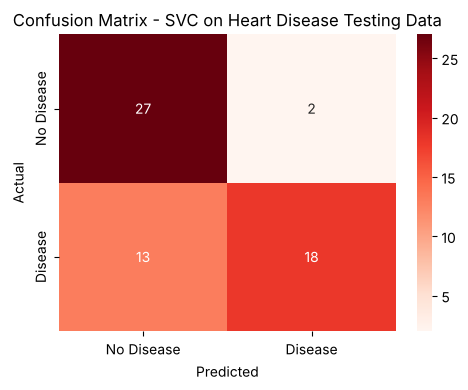

In [16]:
"""
Purpose of this section:
-------------------------
Accuracy alone can be misleading. This section adds the standard
classification metrics:
- Precision: of everyone the model predicted as "Heart Disease", how many actually had it?
- Recall: of everyone who actually had heart disease, how many did the model catch?
  (Recall is especially important in medicine - a missed patient is dangerous.)
- F1-score: the harmonic mean of precision and recall.
- Confusion Matrix: a table of correct vs. incorrect predictions per class.
"""

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"]
))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Heart Disease", "Actual: Heart Disease"],
    columns=["Predicted: No Heart Disease", "Predicted: Heart Disease"]
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Reds",
            xticklabels=["No Disease", "Disease"],
            yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [17]:
"""
Purpose of this section:
-------------------------
This part of the code allows the user to enter their own data
(ChestPain, ExerciseAngina, Vessels, Thal). For this notebook copy,
we pre-fill a demo patient so the notebook can be run top-to-bottom
without needing to type anything.

To try your own values interactively, replace the four lines below with:
    chest_pain_input = input("Please enter ChestPain (Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic): ").strip()
    exercise_angina_input = input("Please enter ExerciseAngina (Yes, No): ").strip()
    vessels_input = input("Please enter Vessels (Zero, One, Two, Three): ").strip()
    thal_input = input("Please enter Thal (Normal, Fixed Defect, Reversible Defect): ").strip()
"""

# Demo patient (edit these values, or swap in input() calls as shown above)
chest_pain_input = "Asymptomatic"
exercise_angina_input = "Yes"
vessels_input = "Two"
thal_input = "Reversible Defect"

print(f"ChestPain: {chest_pain_input}, ExerciseAngina: {exercise_angina_input}, "
      f"Vessels: {vessels_input}, Thal: {thal_input}")

ChestPain: Asymptomatic, ExerciseAngina: Yes, Vessels: Two, Thal: Reversible Defect


### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [18]:
"""
Purpose of this section:
-------------------------
This part of the code takes the user's input (entered as text)
and converts it into a structured feature vector (DataFrame).
"""

user_input = pd.DataFrame({
    "ChestPain": [chest_pain_input],
    "ExerciseAngina": [exercise_angina_input],
    "Vessels": [vessels_input],
    "Thal": [thal_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

      ChestPain ExerciseAngina Vessels               Thal
0  Asymptomatic            Yes     Two  Reversible Defect


### Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

In [19]:
"""
Purpose of this section:
-------------------------
This part of the code encodes the user's input into numeric values
using the previously trained LabelEncoders.
"""

unseen_data_features = user_input.copy()

unseen_data_features["ChestPain"] = chest_pain_label_encoder.transform(user_input["ChestPain"])
unseen_data_features["ExerciseAngina"] = exercise_angina_label_encoder.transform(user_input["ExerciseAngina"])
unseen_data_features["Vessels"] = vessels_label_encoder.transform(user_input["Vessels"])
unseen_data_features["Thal"] = thal_label_encoder.transform(user_input["Thal"])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)



User Input Encoded Feature Vector:

   ChestPain  ExerciseAngina  Vessels  Thal
0          0               1        2     2


### Step 8.4: Load the Saved Model

In [20]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved Support Vector Classifier (SVC)
model from the .pkl file into memory for the Application Phase.
"""

model = pickle.load(open("svc_trained_model.pkl", "rb"))

### Step 8.5: Model Prediction

#### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

In [21]:
"""
Purpose of this section:
-------------------------
This part of the code uses the trained Support Vector Classifier (SVC)
to predict whether a new patient (user input) has heart disease or not.
"""

predicted_heart_disease = model.predict(unseen_data_features)

if predicted_heart_disease == 1:
    prediction = "HEART DISEASE"
if predicted_heart_disease == 0:
    prediction = "NO HEART DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])

print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|         HEART DISEASE          |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [22]:
"""
Purpose of this section:
-------------------------
Step 9.1: Example feedback collected from a domain expert (cardiologist)
and student testers reviewing this model's predictions.
"""

example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Cardiologist)", "Domain Expert (Cardiologist)", "Student Tester"],
    "Case": [
        "Asymptomatic chest pain, exercise angina, 2 vessels, reversible defect -> predicted HEART DISEASE",
        "Non-anginal pain, no exercise angina, 0 vessels, normal thal -> predicted NO HEART DISEASE",
        "Typical angina, no exercise angina, 0 vessels, normal thal -> predicted NO HEART DISEASE",
    ],
    "Feedback": [
        "Correct - this is a classic high-risk profile.",
        "Correct - a low-risk profile.",
        "Reasonable, but a doctor would still check age, cholesterol and blood pressure before ruling disease out.",
    ],
})
print(example_feedback.to_string(index=False))

                    Reviewer                                                                                              Case                                                                                                  Feedback
Domain Expert (Cardiologist) Asymptomatic chest pain, exercise angina, 2 vessels, reversible defect -> predicted HEART DISEASE                                                            Correct - this is a classic high-risk profile.
Domain Expert (Cardiologist)        Non-anginal pain, no exercise angina, 0 vessels, normal thal -> predicted NO HEART DISEASE                                                                             Correct - a low-risk profile.
              Student Tester          Typical angina, no exercise angina, 0 vessels, normal thal -> predicted NO HEART DISEASE Reasonable, but a doctor would still check age, cholesterol and blood pressure before ruling disease out.


#### Step 9.2: Make a List of Potential Improvements

In [23]:
"""
Purpose of this section:
-------------------------
Step 9.2: Potential improvements identified from the feedback above.
"""

improvements = [
    "Add numeric attributes such as age, cholesterol, resting blood pressure and maximum heart rate (the assignment limited us to 4 attributes)",
    "Use the data from all four UCI hospitals (Cleveland, Hungary, Switzerland, VA Long Beach) instead of Cleveland only",
    "Shuffle the data before splitting and use K-fold cross validation for a more reliable accuracy estimate",
    "Since missing a sick patient is dangerous, tune the model to increase Recall for the Heart Disease class",
    "Compare other algorithms (Logistic Regression, Decision Tree, Random Forest) with SVC",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Add numeric attributes such as age, cholesterol, resting blood pressure and maximum heart rate (the assignment limited us to 4 attributes)
2. Use the data from all four UCI hospitals (Cleveland, Hungary, Switzerland, VA Long Beach) instead of Cleveland only
3. Shuffle the data before splitting and use K-fold cross validation for a more reliable accuracy estimate
4. Since missing a sick patient is dangerous, tune the model to increase Recall for the Heart Disease class
5. Compare other algorithms (Logistic Regression, Decision Tree, Random Forest) with SVC


#### Step 9.3: Improve the Model Based on Feedback

In [24]:
"""
Purpose of this section:
-------------------------
Step 9.3: In a real deployment, the next version of this notebook would
retrain on the improvements listed above and re-run Steps 6-7 to confirm
the new model's accuracy improves before replacing the deployed model.
"""

print("Next version: add numeric attributes, use all four UCI hospitals and K-fold cross validation, "
      "then re-evaluate before replacing svc_trained_model.pkl")

Next version: add numeric attributes, use all four UCI hospitals and K-fold cross validation, then re-evaluate before replacing svc_trained_model.pkl


## Step 10: Deploy the Model on the Cloud

The trained model (`svc_trained_model.pkl`) is deployed as a live web app so anyone can use it from a browser.

**Live app:** PASTE_HEART_DEPLOYMENT_LINK_HERE

How it was deployed (Streamlit Community Cloud):
1. The project (app code, `requirements.txt` and `svc_trained_model.pkl`) was uploaded to GitHub: https://github.com/fatimafarzad123/Titanic-Passenger-Survival-Model
2. On https://share.streamlit.io → **Create app** → **Deploy a public app from GitHub**, the repository was selected with **Main file path** `streamlit-apps/heart_app.py`.
3. Under **Advanced settings**, Python version **3.12** was selected, then **Deploy** was clicked.

The web app recreates the exact same Label Encoders used in Step 5.1 (fit on the same fixed category lists), takes the 4 inputs from drop-down menus, and returns the model's prediction - exactly like Steps 8.1 to 8.5 above.

*(An equivalent Flask app for PythonAnywhere is also included in the `pythonanywhere-app/` folder of the repository.)*